# Лабораторна робота №2
## Зниження розмірності, кластеризація та класифікація текстових даних

Виконав: ФБ-62мп Мартинюк Іван

**Мета роботи:** ознайомитися з базовими методами навчання без учителя та обробки текстових даних: зниженням розмірності, візуалізацією і кластеризацією даних, а також побудовою базового workflow класифікації текстів з використанням бібліотеки Scikit-learn.

In [1]:
import time
import re

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import classification_report, silhouette_score

from wordcloud import WordCloud

## Дані з ЛР1

Для частин 1 і 2 використано датасет RT-IoT2022 з ЛР1 з тією самою обробкою: видалено індекс, порт джерела, константну колонку, дублікати і клас `NMAP_FIN_SCAN`, а `proto` і `service` закодовано через one-hot.

In [2]:
df = pd.read_csv('../lab1/rt-iot2022/RT_IOT2022')
df = df.drop(columns=['Unnamed: 0', 'id.orig_p', 'bwd_URG_flag_count'])
df = df.drop_duplicates()
df = df[df['Attack_type'] != 'NMAP_FIN_SCAN']

ohe = OneHotEncoder(sparse_output=False)
cat_encoded = ohe.fit_transform(df[['proto', 'service']])
cat_df = pd.DataFrame(cat_encoded, columns=ohe.get_feature_names_out(['proto', 'service']), index=df.index)
df = pd.concat([df.drop(columns=['proto', 'service']), cat_df], axis=1)

X = df.drop(columns=['Attack_type'])
y = df['Attack_type']
print(X.shape)

(23834, 92)


## 1. Зниження розмірності та візуалізація даних

### PCA

PCA залежить від масштабу ознак, тому дані спершу стандартизовано. `n_components=0.95` означає, що залишається стільки компонент, скільки потрібно, щоб пояснити 95% дисперсії. Для порівняння використано kNN (`n_neighbors=5`) з ЛР1.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
scaled_X_train = scaler.fit_transform(X_train)
scaled_X_test = scaler.transform(X_test)

pca = PCA(n_components=0.95)
pca_X_train = pca.fit_transform(scaled_X_train)
pca_X_test = pca.transform(scaled_X_test)

print('Ознак до PCA:', scaled_X_train.shape[1])
print('Компонент після PCA:', pca.n_components_)

Ознак до PCA: 92
Компонент після PCA: 32


In [4]:
def fit_eval(X_tr, X_te, label):
    knn = KNeighborsClassifier(n_neighbors=5)
    t0 = time.perf_counter()
    knn.fit(X_tr, y_train)
    t1 = time.perf_counter()
    y_pred = knn.predict(X_te)
    t2 = time.perf_counter()
    print(label)
    print('fit: %.3f s, predict: %.3f s' % (t1 - t0, t2 - t1))
    print(classification_report(y_test, y_pred, digits=3))

fit_eval(scaled_X_train, scaled_X_test, 'kNN без PCA')
fit_eval(pca_X_train, pca_X_test, 'kNN з PCA')

kNN без PCA
fit: 0.020 s, predict: 0.267 s
                            precision    recall  f1-score   support

            ARP_poisioning      0.966     0.977     0.972      1060
            DDOS_Slowloris      0.933     0.907     0.919       107
             DOS_SYN_Hping      1.000     1.000     1.000        11
              MQTT_Publish      0.996     0.998     0.997       828
Metasploit_Brute_Force_SSH      1.000     0.714     0.833         7
         NMAP_OS_DETECTION      0.997     1.000     0.999       380
             NMAP_TCP_scan      0.985     0.990     0.988       200
             NMAP_UDP_SCAN      0.939     0.939     0.939       230
       NMAP_XMAS_TREE_SCAN      1.000     0.997     0.999       379
               Thing_Speak      0.984     0.982     0.983      1521
                Wipro_bulb      0.923     0.818     0.867        44

                  accuracy                          0.981      4767
                 macro avg      0.975     0.938     0.954      4767
   

kNN з PCA
fit: 0.015 s, predict: 0.210 s
                            precision    recall  f1-score   support

            ARP_poisioning      0.965     0.979     0.972      1060
            DDOS_Slowloris      0.933     0.907     0.919       107
             DOS_SYN_Hping      1.000     1.000     1.000        11
              MQTT_Publish      0.994     0.998     0.996       828
Metasploit_Brute_Force_SSH      1.000     0.714     0.833         7
         NMAP_OS_DETECTION      1.000     1.000     1.000       380
             NMAP_TCP_scan      0.985     0.990     0.988       200
             NMAP_UDP_SCAN      0.943     0.939     0.941       230
       NMAP_XMAS_TREE_SCAN      1.000     0.997     0.999       379
               Thing_Speak      0.985     0.981     0.983      1521
                Wipro_bulb      0.921     0.795     0.854        44

                  accuracy                          0.981      4767
                 macro avg      0.975     0.936     0.953      4767
     

PCA зменшив кількість ознак з 92 до 32, тобто приблизно втричі. Так вийшло, бо багато ознак сильно корелюють між собою (у ЛР1 було 56 пар з кореляцією понад 0,95).

Якість майже не змінилась: accuracy 0,981 в обох випадках, macro F1 0,954 без PCA і 0,953 з PCA. Час навчання майже нульовий і там, і там, бо kNN під час `fit` лише запам'ятовує дані. Час передбачення з PCA менший, бо відстані рахуються по 32 компонентах, а не по 92 ознаках (точні значення трохи відрізняються від запуску до запуску).

### t-SNE

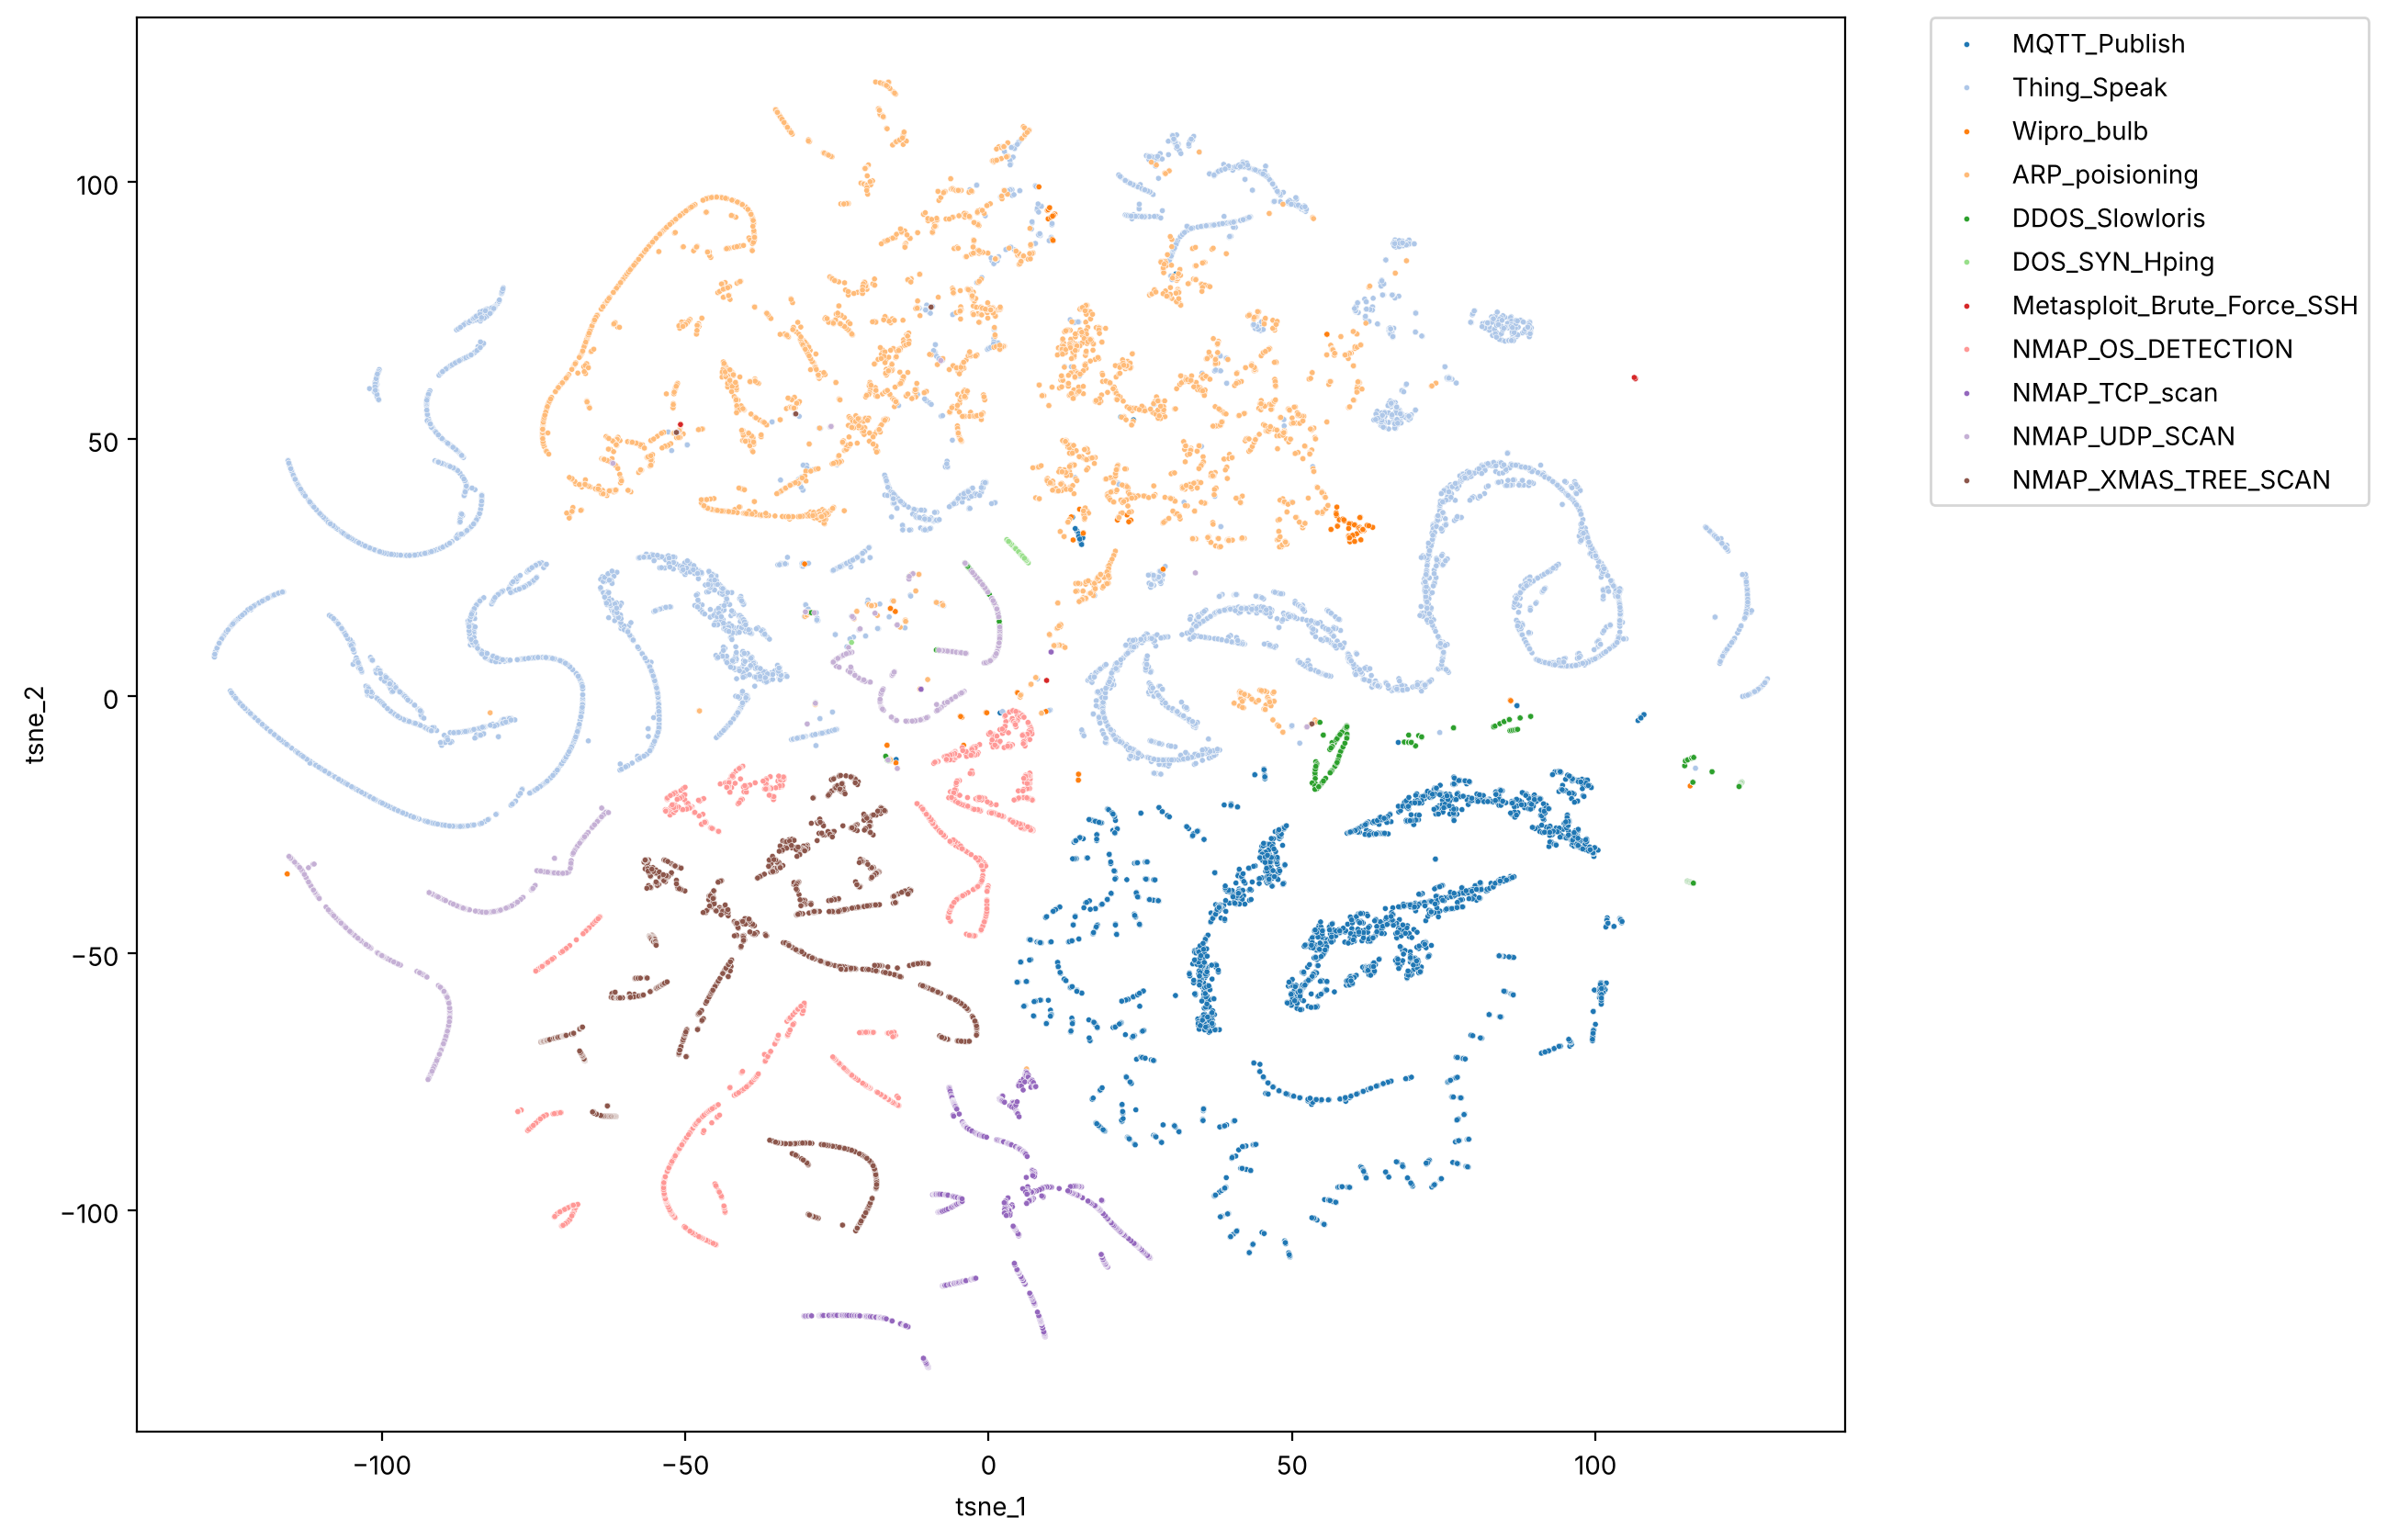

In [5]:
scaled_X = StandardScaler().fit_transform(X)
tsne_result = TSNE(n_components=2, random_state=42).fit_transform(scaled_X)

tsne_df = pd.DataFrame({'tsne_1': tsne_result[:,0], 'tsne_2': tsne_result[:,1], 'label': y.values})

fig, ax = plt.subplots(1, figsize=(12,10))
sns.scatterplot(x='tsne_1', y='tsne_2', hue='label', data=tsne_df, ax=ax, s=5, palette='tab20')
ax.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.0)
plt.show()

Більшість класів на графіку утворюють окремі групи: `MQTT_Publish`, сканування nmap, `DDOS_Slowloris`, `DOS_SYN_Hping`. `Thing_Speak` і `ARP_poisioning` розкидані по великій площі й частково перемішані. Ці два класи найчастіше плутали і моделі в ЛР1.

## 2. Кластерний аналіз

Для кластеризації залишено три класи: `Thing_Speak`, `MQTT_Publish` і `NMAP_OS_DETECTION`. Це два види звичайного трафіку IoT-пристроїв і сканування мережі, і в кожному класі достатньо записів. Мітки класів у кластеризації не використовуються, лише для порівняння в кінці.

In [6]:
df_cl = df[df['Attack_type'].isin(['Thing_Speak', 'MQTT_Publish', 'NMAP_OS_DETECTION'])]
X_cl = StandardScaler().fit_transform(df_cl.drop(columns=['Attack_type']))
y_cl = df_cl['Attack_type']
y_cl.value_counts()

Attack_type
Thing_Speak          7602
MQTT_Publish         4141
NMAP_OS_DETECTION    1899
Name: count, dtype: int64

### Elbow Method

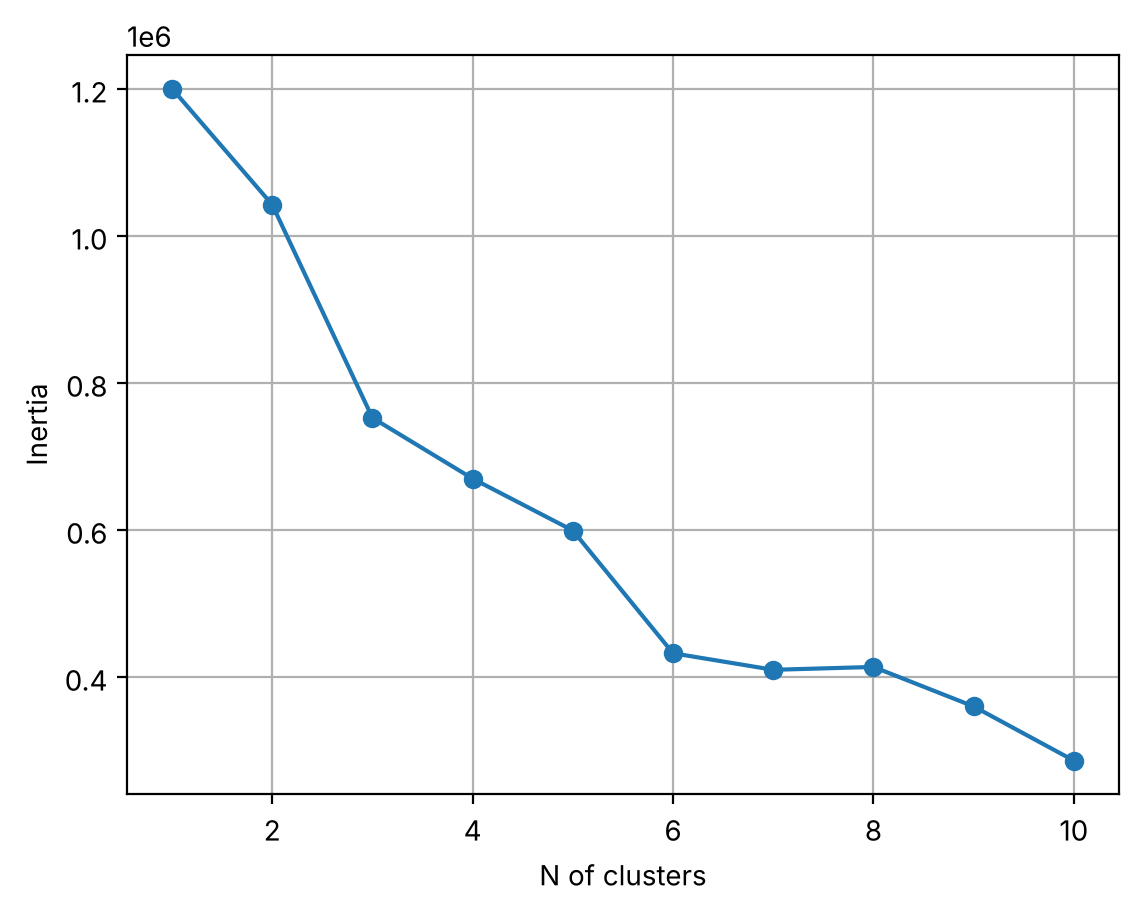

In [7]:
Error = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(X_cl)
    Error.append(kmeans.inertia_)

plt.plot(range(1, 11), Error, marker='o')
plt.xlabel('N of clusters')
plt.ylabel('Inertia')
plt.grid()
plt.show()

### Silhouette Score

In [8]:
for i in range(2, 11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans_labels = kmeans.fit_predict(X_cl)
    print('For n_clusters =', i, ' silhouette average:', round(silhouette_score(X_cl, kmeans_labels), 3))

For n_clusters = 2  silhouette average: 0.484


For n_clusters = 3  silhouette average: 0.569


For n_clusters = 4  silhouette average: 0.571


For n_clusters = 5  silhouette average: 0.668


For n_clusters = 6  silhouette average: 0.671


For n_clusters = 7  silhouette average: 0.672


For n_clusters = 8  silhouette average: 0.614


For n_clusters = 9  silhouette average: 0.623


For n_clusters = 10  silhouette average: 0.707


На графіку Elbow найбільше падіння inertia між k = 2 і k = 3, далі спад повільніший. Silhouette теж помітно росте від k = 2 до k = 3 (0,484 і 0,569). При більших k silhouette росте й далі, бо всередині класів є менші підгрупи потоків, але для порівняння з трьома класами взято k = 3.

In [9]:
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(X_cl)

Кластери показано у 2D через t-SNE. На проєкції PCA один викидний потік розтягує осі, і решта точок зливається в одну пляму.

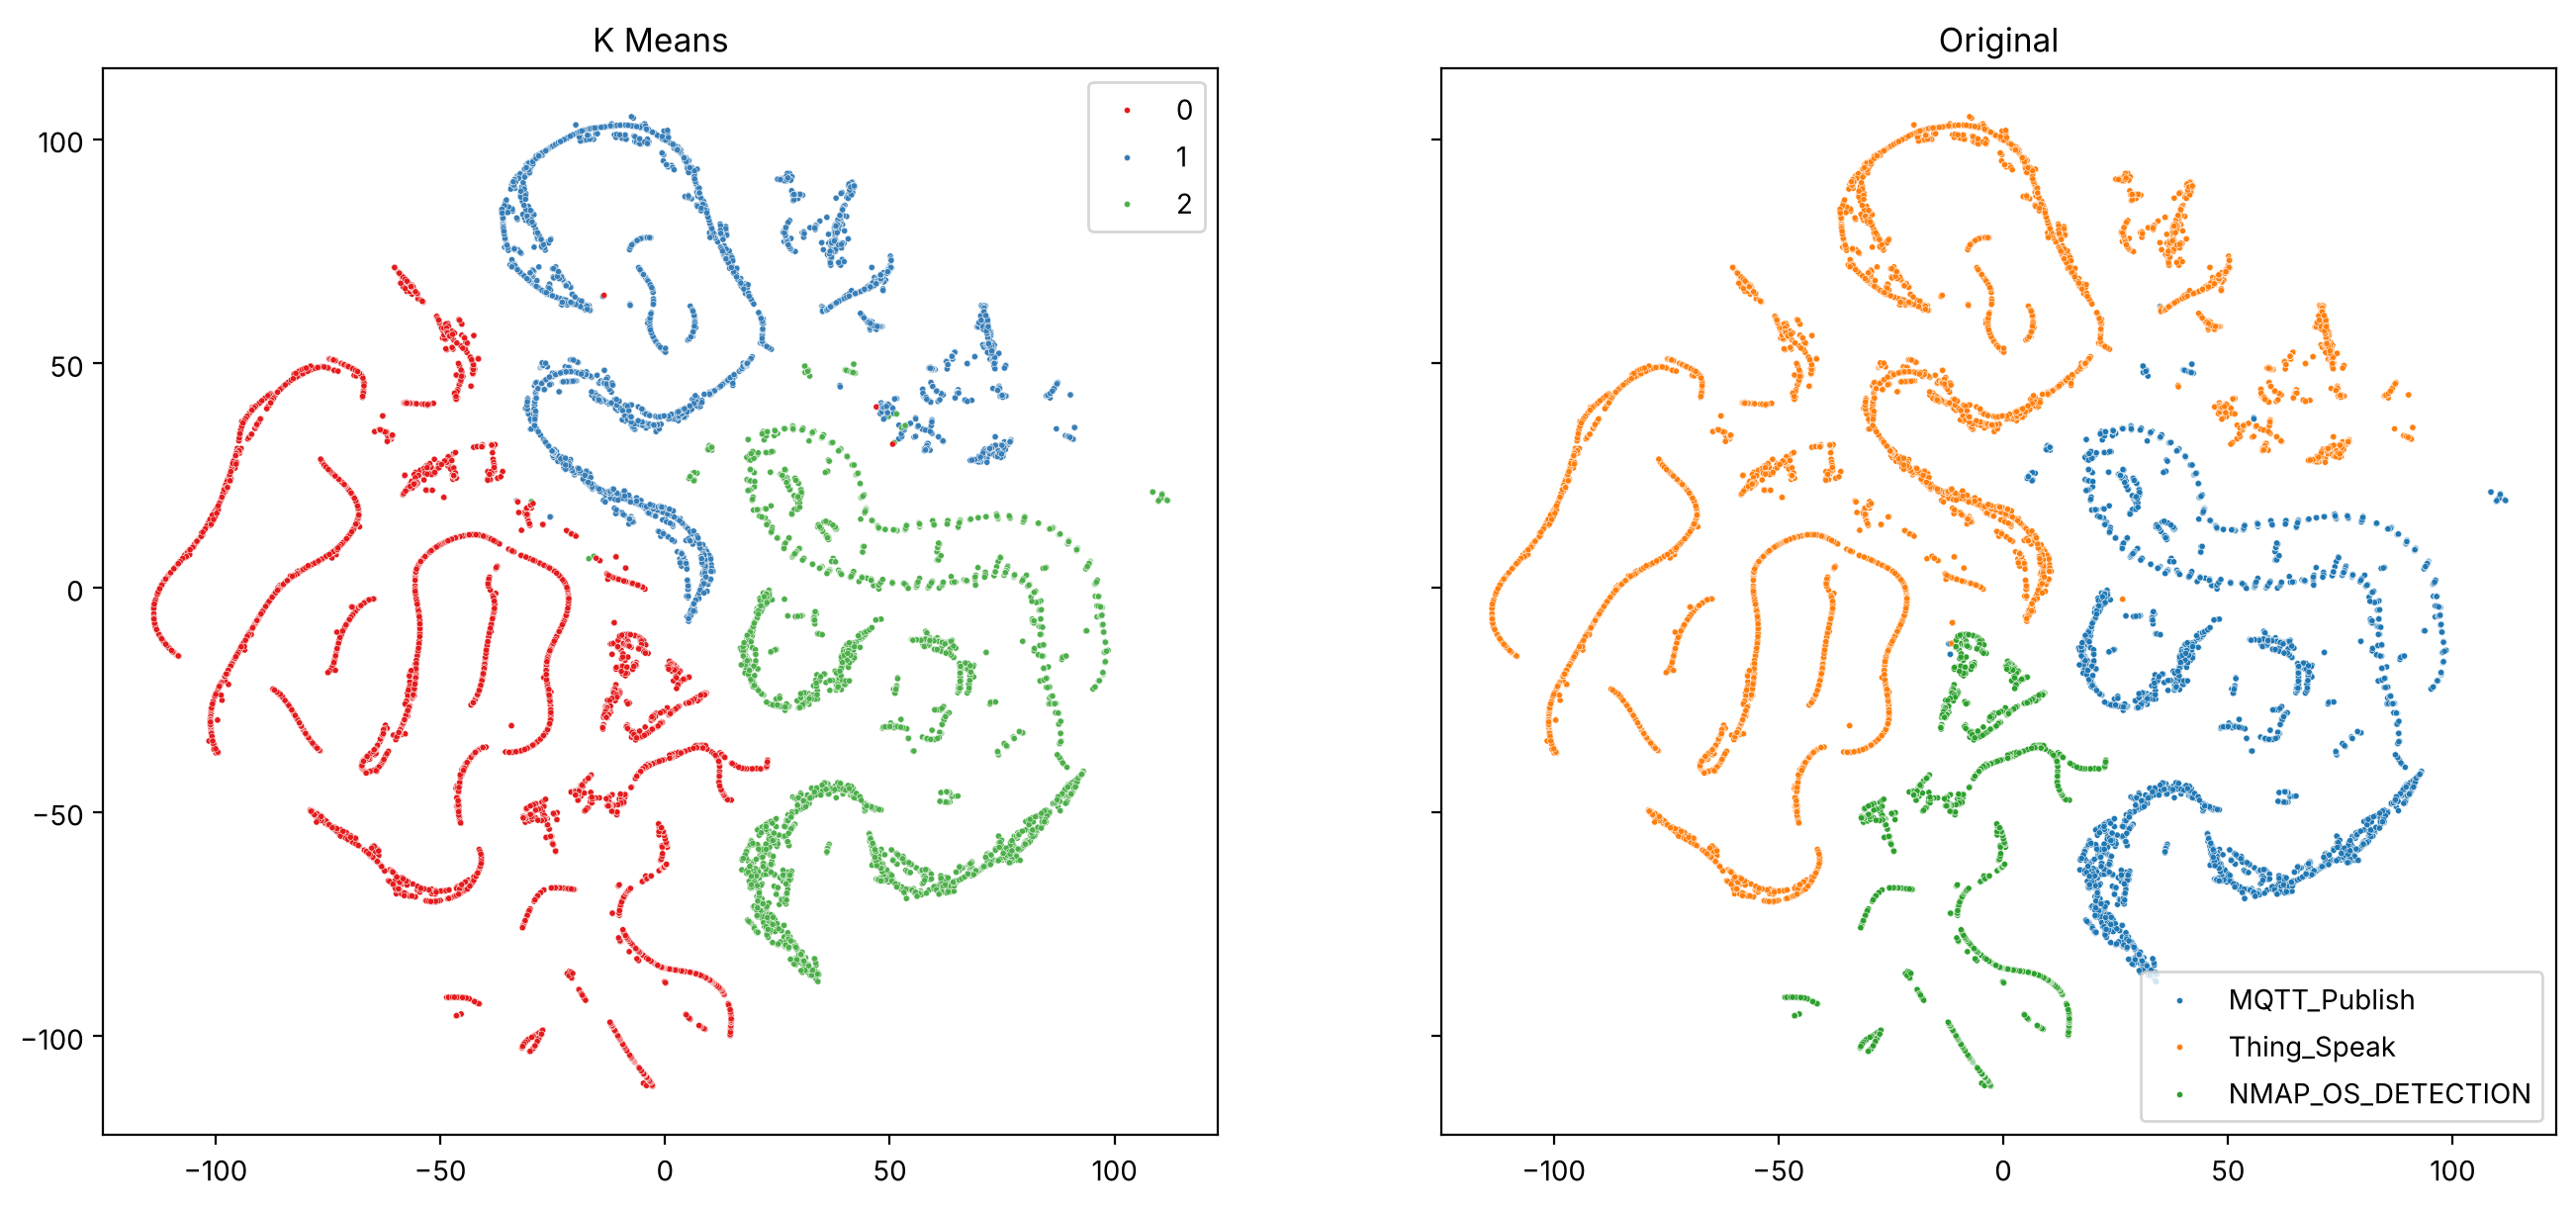

In [10]:
X_cl_2d = TSNE(n_components=2, random_state=42).fit_transform(X_cl)

f, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize=(16,7))
ax1.set_title('K Means')
sns.scatterplot(x=X_cl_2d[:,0], y=X_cl_2d[:,1], hue=clusters, palette='Set1', s=5, ax=ax1)
ax2.set_title('Original')
sns.scatterplot(x=X_cl_2d[:,0], y=X_cl_2d[:,1], hue=y_cl.values, s=5, ax=ax2)
plt.show()

In [11]:
pd.crosstab(y_cl, clusters)

col_0,0,1,2
Attack_type,,,
MQTT_Publish,5,3,4133
NMAP_OS_DETECTION,1899,0,0
Thing_Speak,3971,3609,22


In [12]:
df_cl.assign(cluster=clusters).groupby(['cluster', 'Attack_type'])[['proto_udp', 'service_dns']].mean().round(2)

proto_udp  service_dns
cluster Attack_type                              
0       MQTT_Publish            0.00         0.00
        NMAP_OS_DETECTION       0.00         0.00
        Thing_Speak             0.99         0.96
1       MQTT_Publish            0.00         0.00
        Thing_Speak             0.01         0.00
2       MQTT_Publish            0.00         0.00
        Thing_Speak             0.32         0.18

Кластери збігаються з класами лише частково. Кластер 2 майже повністю складається з `MQTT_Publish`. Усі потоки `NMAP_OS_DETECTION` потрапили в кластер 0, але там же опинилась приблизно половина `Thing_Speak`, а друга половина утворила кластер 1.

З останньої таблиці видно, що `Thing_Speak` у кластері 0 майже повністю складається з DNS-запитів по UDP, а в кластері 1 з TCP-з'єднань. Короткі DNS-запити за ознаками схожі на потоки сканування, тому K-Means об'єднав їх. Тобто K-Means розділив дані за типом потоку, і знайдена кластерна структура класам не відповідає.

## 3. Обробка та класифікація текстових даних

Датасет: TRAM від MITRE Center for Threat-Informed Defense ([GitHub](https://github.com/center-for-threat-informed-defense/tram), файл `data/tram2-data/single_label.json`). Це речення зі звітів кіберрозвідки, розмічені техніками MITRE ATT&CK. Технік у датасеті 50, залишено три:

* `T1027` Obfuscated Files or Information: шифрування, кодування, упаковка коду чи даних;
* `T1140` Deobfuscate/Decode Files or Information: розшифрування і декодування;
* `T1059.003` Windows Command Shell: виконання команд через `cmd.exe`.

In [13]:
tram = pd.read_json('tram_single_label.json')
print(tram.shape)
tram.head()

(5089, 3)


,text,label,doc_title
0,This file extracts credentials from LSASS simi...,T1003.001,NotPetya Technical Analysis A Triple Threat F...
1,It calls OpenProcess on lsass.exe with access ...,T1003.001,NotPetya Technical Analysis A Triple Threat F...
2,It spreads to Microsoft Windows machines using...,T1210,NotPetya Technical Analysis A Triple Threat F...
3,SMB exploitation via EternalBlue,T1210,NotPetya Technical Analysis A Triple Threat F...
4,SMBv1 Exploitation via EternalBlue,T1210,NotPetya Technical Analysis A Triple Threat F...


In [14]:
techniques = {'T1027': 'T1027_Obfuscation', 'T1140': 'T1140_Deobfuscate', 'T1059.003': 'T1059.003_cmd'}

texts = tram[tram['label'].isin(techniques.keys())].copy()
texts['technique'] = texts['label'].map(techniques)
texts['technique'].value_counts()

technique
T1027_Obfuscation    685
T1140_Deobfuscate    455
T1059.003_cmd        345
Name: count, dtype: int64

In [15]:
print(texts.isnull().sum().sum())
print(texts['text'].duplicated().sum())

0
123


Пропусків немає, але 123 речення повторюються в різних звітах. Як і в ЛР1, дублікати видалено.

In [16]:
texts = texts.drop_duplicates(subset='text')
texts['technique'].value_counts()

technique
T1027_Obfuscation    671
T1140_Deobfuscate    435
T1059.003_cmd        256
Name: count, dtype: int64

### Передобробка

Текст переводиться в нижній регістр, видаляються посилання, пунктуація, цифри, стоп-слова (`ENGLISH_STOP_WORDS`) і слова з однієї літери.

In [17]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    words = [w for w in text.split() if w not in ENGLISH_STOP_WORDS and len(w) > 1]
    return ' '.join(words)

texts['clean'] = texts['text'].apply(clean_text)
texts[['text', 'clean']].head()

,text,clean
10,The malware decompresses its resource named,malware decompresses resource named
11,The malware decompresses a resource,malware decompresses resource
12,This is used as an integrity check for the dec...,used integrity check decryption process
13,"decrypt the MFT,",decrypt mft
14,the code attempts to decrypt the contents,code attempts decrypt contents


### WordCloud

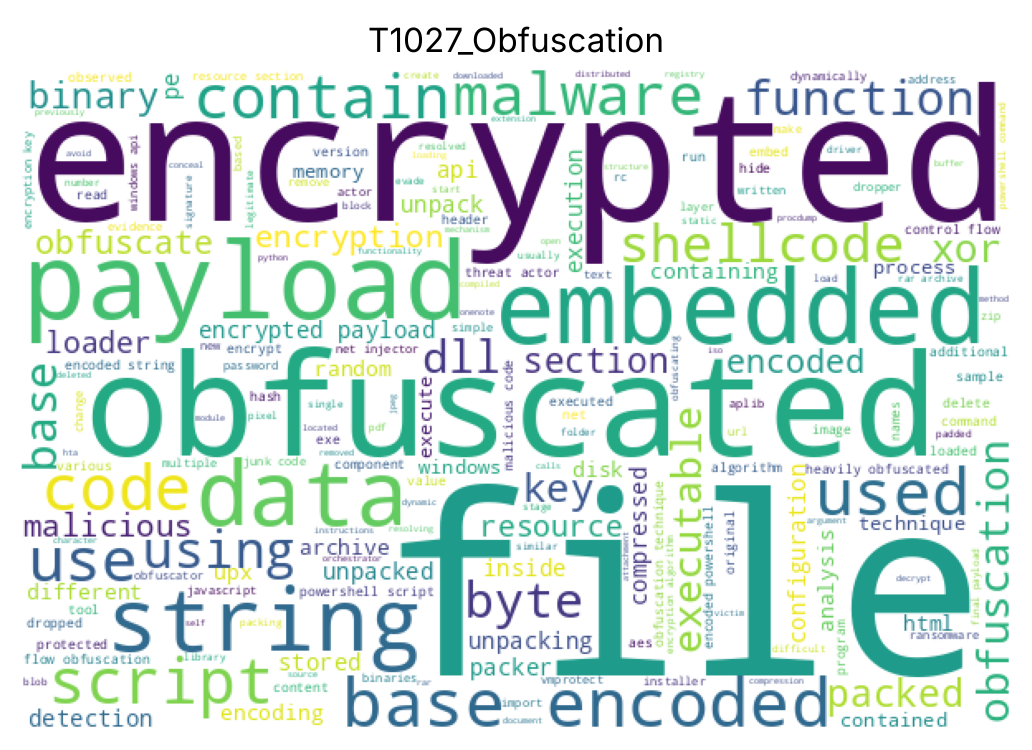

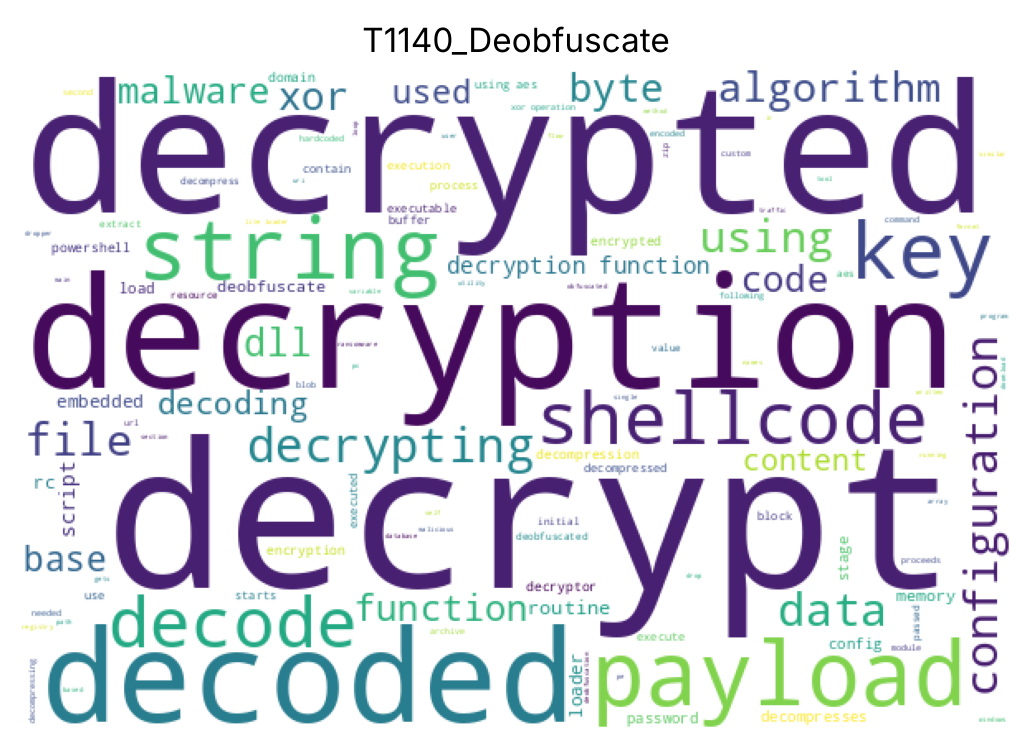

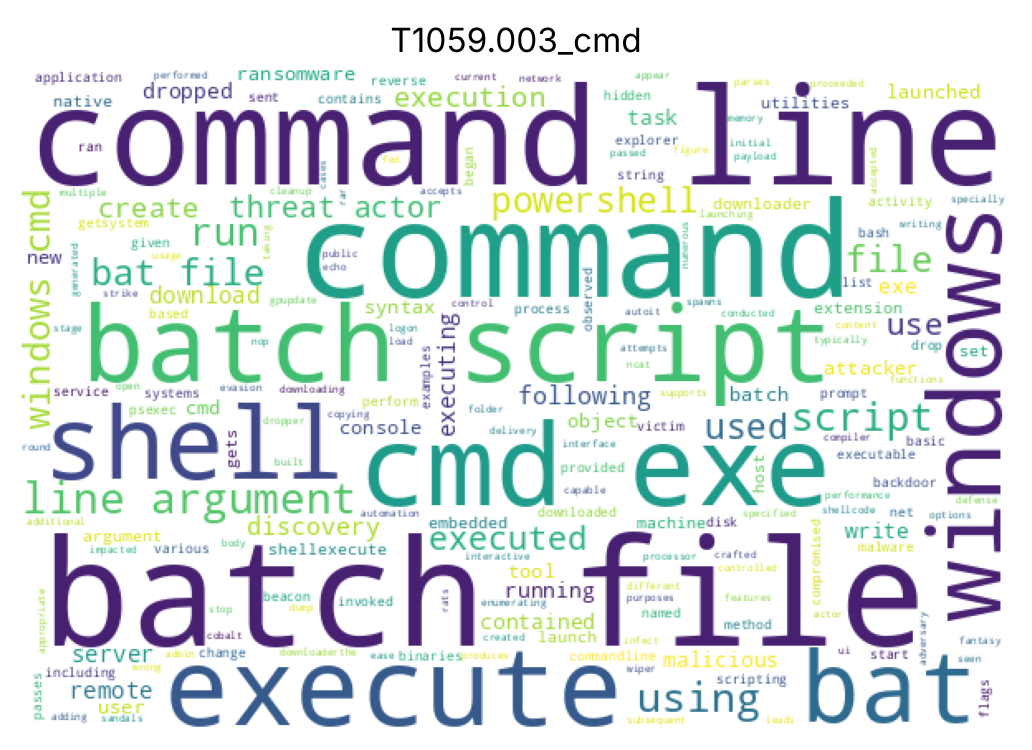

In [18]:
def visualize(label):
    text = ' '.join(texts[texts['technique'] == label]['clean'])
    wordcloud = WordCloud(width=600, height=400, background_color='white', random_state=42).generate(text)
    plt.imshow(wordcloud)
    plt.axis('off')
    plt.title(label)
    plt.show()

for label in techniques.values():
    visualize(label)

Для T1027 найчастіші слова «encrypted», «obfuscated», «encoded», «packed», для T1140 «decrypt», «decrypted», «decode», «decoded». Ці техніки описують протилежні дії (зашифрувати і розшифрувати), тому відрізняються переважно формою тих самих слів, а багато слів у них спільні: «payload», «string», «shellcode», «xor». Для T1059.003 характерні «command line», «batch file», «cmd exe», і за лексикою ця техніка відрізняється від двох інших найбільше.

### Векторизація і класифікація

In [19]:
X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(texts['clean'], texts['technique'], test_size=0.20, random_state=42, stratify=texts['technique'])

tfidf_vectorizer = TfidfVectorizer(min_df=2)
tfidf_train = tfidf_vectorizer.fit_transform(X_train_t)
tfidf_test = tfidf_vectorizer.transform(X_test_t)
print(tfidf_train.shape)

(1089, 544)


In [20]:
clf = LogisticRegression(max_iter=1000)
clf.fit(tfidf_train, y_train_t)
predicted = clf.predict(tfidf_test)

print(classification_report(y_test_t, predicted, digits=3))

                   precision    recall  f1-score   support

T1027_Obfuscation      0.924     0.993     0.957       135
    T1059.003_cmd      0.979     0.902     0.939        51
T1140_Deobfuscate      1.000     0.931     0.964        87

         accuracy                          0.956       273
        macro avg      0.968     0.942     0.953       273
     weighted avg      0.959     0.956     0.956       273



In [21]:
pd.crosstab(y_test_t, predicted)

col_0,T1027_Obfuscation,T1059.003_cmd,T1140_Deobfuscate
technique,,,
T1027_Obfuscation,134,1,0
T1059.003_cmd,5,46,0
T1140_Deobfuscate,6,0,81


Accuracy 0,956, macro F1 0,953. Найнижчий recall у `T1059.003_cmd` (0,902) і `T1140_Deobfuscate` (0,931). Майже всі помилки (11 з 12) модель віднесла до `T1027_Obfuscation`, найбільшого класу: коли в реченні немає характерних слів, перевагу отримує клас, якого в навчальних даних більше.

## Висновки

1. PCA зменшив кількість ознак з 92 до 32 (95% дисперсії). Якість kNN майже не змінилась (macro F1 0,954 і 0,953), час навчання як був близький до нуля, так і лишився, а передбачення стало швидшим.
2. На t-SNE більшість класів утворюють окремі групи, крім `Thing_Speak` і `ARP_poisioning`, які перемішані.
3. K-Means з k = 3 виділив `MQTT_Publish` в окремий кластер, а решту даних розділив за типом потоку: DNS-запити ThingSpeak потрапили в один кластер зі скануванням nmap. Кластерна структура з класами не збігається.
4. Класифікація речень TRAM за технікою ATT&CK (TF-IDF + логістична регресія) дала accuracy 0,956 і macro F1 0,953. Помилки здебільшого в бік найбільшого класу T1027.